#### Batch-normalization of cerebellar and medulloblastoma microarray gene expression datasets

Load Data

In [1]:
import pandas as pd
import os

# Set working directory 
path = os.path.dirname(r'E:\Brain Cancer\GSE_124814\Py-Machine')
print(os.listdir())

# Load expression matrix
expression_df = pd.read_csv(r'GSE124814_HW_expr_matrix.tsv', sep="\t")

# Load description data
description_df = pd.read_excel(r'GSE124814_sample_descriptions.xlsx', header=1)


['GSE124814_HW_expr_matrix.tsv', 'GSE124814_sample_descriptions.xlsx', 'Python-MachineLearning.ipynb']


In [ ]:
# Show expression dataset
print("Expression dataset dimention: ", expression_df.shape)
expression_df.head(10)

Expression dataset dimention:  (14883, 1642)


,Gene_Symbol,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,Sample_9,...,Sample_1632,Sample_1633,Sample_1634,Sample_1635,Sample_1636,Sample_1637,Sample_1638,Sample_1639,Sample_1640,Sample_1641
0,A1CF,-0.019300,0.059848,-0.092846,-0.097767,0.118738,0.107071,-0.066334,0.065494,-0.004831,...,-0.250330,-0.050667,-0.119461,-0.243639,0.117456,0.294824,0.136340,0.032109,0.118904,-0.093326
1,A2M,0.289494,0.230734,-0.089454,0.314725,1.391229,-0.127206,-0.289878,-0.229529,-0.718827,...,-0.969275,0.353018,1.218646,0.036988,-0.395216,-0.286654,-0.736301,1.367207,-0.443458,-0.176276
2,A2ML1,0.213732,0.040908,-0.086623,-0.094998,0.038038,-0.119666,-0.201175,-0.096457,-0.078605,...,-0.117240,0.142522,-0.103750,0.232430,0.388421,0.044569,-0.051096,-0.004696,-0.149248,0.141412
3,A4GALT,-0.402028,-0.381666,-0.586763,-0.784063,-0.242232,-0.416652,0.984401,-0.458620,-0.734444,...,-0.574012,-0.412380,0.823832,-0.329619,-0.242285,0.678984,0.538960,-0.210197,-0.579546,-0.618990
4,A4GNT,0.030517,-0.145988,-0.245097,-0.297410,-0.050874,-0.094500,-0.110440,0.023204,-0.139346,...,0.316020,-0.298627,0.050016,0.046728,-0.012474,-0.289700,-0.101211,0.054734,0.270025,0.026565
5,AAAS,-0.112330,0.092463,-0.015891,0.557690,0.067459,0.315252,0.769366,-0.306924,0.460333,...,0.169089,-0.113830,-0.106375,-0.086416,0.123474,0.067939,-0.110582,-0.314652,-0.151946,0.022220
6,AACS,0.327182,1.071961,0.164045,1.297581,0.037079,0.323277,-0.445215,-0.143695,0.635335,...,0.020511,-0.182872,-0.744527,0.559042,-0.338556,-1.398416,-1.284305,-0.335415,0.787653,0.527620
7,AADAC,0.243028,0.072346,-0.078648,0.213874,0.061993,-0.001862,-0.008299,-0.024627,0.203997,...,0.136168,0.015690,0.179920,-0.088545,0.268423,0.067492,-0.078472,0.192733,0.310424,0.275131
8,AADACL2,-0.379652,-0.196808,-0.020103,0.050398,-0.114732,-0.153843,0.083798,0.027806,-0.160299,...,-0.115429,0.118802,0.114633,0.084993,-0.100363,0.148449,0.340775,0.107092,0.095418,0.310875
9,AADAT,-0.779346,0.020437,0.239080,0.998270,-0.777357,-0.970272,-0.098314,-0.423325,0.346425,...,0.416386,-0.230589,-0.615714,-0.306836,-0.286017,-0.708411,0.601070,-0.213071,-0.313820,-0.621746


In [ ]:
# show description dataset
print("Description dataset dimention: ", description_df.shape)
description_df.head(4)

Description dataset dimention:  (1641, 20)


,Sample name,title,CEL file,source name,organism,molecule,label,chip name,characteristics: age,characteristics: gender,characteristics: histology,characteristics: brain region,characteristics: death,characteristics: metastatic stage,characteristics: follow up,characteristics: subgroup supplied original,characteristics: subgroup supplied renamed,characteristics: subgroup relabeled,description,description.1
0,Sample_1,EMTAB292-A195-1-2,Reanalysis of existing record,Medulloblastoma,Homo sapiens,total_RNA,biotin,HuEx-1-0-st-v1,6.5 years,female,anaplastic,cerebellum,NaN,NaN,NaN,Unknown,Unknown,G4,reanalysis of A195_1_2 (E-MTAB-292),Sample_1
1,Sample_2,EMTAB292-A195-10-2,Reanalysis of existing record,Medulloblastoma,Homo sapiens,total_RNA,biotin,HuEx-1-0-st-v1,5.7 years,male,classic,cerebellum,NaN,NaN,NaN,Unknown,Unknown,G4,reanalysis of A195_10_2 (E-MTAB-292),Sample_2
2,Sample_3,EMTAB292-A195-11-2,Reanalysis of existing record,Medulloblastoma,Homo sapiens,total_RNA,biotin,HuEx-1-0-st-v1,8.1 years,female,anaplastic,cerebellum,NaN,NaN,NaN,Unknown,Unknown,G4,reanalysis of A195_11_2 (E-MTAB-292),Sample_3
3,Sample_4,EMTAB292-A195-12-2,Reanalysis of existing record,Medulloblastoma,Homo sapiens,total_RNA,biotin,HuEx-1-0-st-v1,1.9 years,male,anaplastic,cerebellum,NaN,NaN,NaN,Unknown,Unknown,G3,reanalysis of A195_12_2 (E-MTAB-292),Sample_4


Data Cleaning & Preprocessing

In [ ]:
# All missing values in datasets
print("Missing values in expression dataset: ", expression_df.isnull().sum().sum())
print("Missing values in description dataset: ", description_df.isnull().sum().sum())

Missing values in expression dataset:  0
Missing values in description dataset:  6176


In [ ]:
# Select columns in description dataset
print(description_df.columns)
description_df = description_df[['Sample name', 'source name', 'characteristics: gender', 
                                'characteristics: brain region']]

description_df = description_df.set_index('Sample name')

description_df.head(12)

Index(['Sample name', 'title', 'CEL file', 'source name', 'organism',
       'molecule', 'label', 'chip name', 'characteristics: age',
       'characteristics: gender', 'characteristics: histology',
       'characteristics: brain region', 'characteristics: death',
       'characteristics: metastatic stage', 'characteristics: follow up',
       'characteristics: subgroup supplied original',
       'characteristics: subgroup supplied renamed',
       'characteristics: subgroup relabeled', 'description', 'description.1'],
      dtype='object')


,source name,characteristics: gender,characteristics: brain region
Sample name,,,
Sample_1,Medulloblastoma,female,cerebellum
Sample_2,Medulloblastoma,male,cerebellum
Sample_3,Medulloblastoma,female,cerebellum
Sample_4,Medulloblastoma,male,cerebellum
Sample_5,Medulloblastoma,male,cerebellum
Sample_6,Medulloblastoma,male,cerebellum
Sample_7,Medulloblastoma,female,cerebellum
Sample_8,Medulloblastoma,male,cerebellum
Sample_9,Medulloblastoma,female,cerebellum


In [ ]:
# Description dataset value counts
for col in description_df.columns:
    print(f"\n==========")
    print(description_df[col].value_counts())

# Description dataset null values
print(f"\n=========== null ============")
print("Source name: ",description_df['source name'].isnull().sum())
print("gender name: ",description_df['characteristics: gender'].isnull().sum())
print("brain region: ",description_df['characteristics: brain region'].isnull().sum())



source name
Medulloblastoma    1350
Normal              291
Name: count, dtype: int64

characteristics: gender
M            640
F            345
male         288
female       150
m             15
f              7
mixed_sex      1
               1
Name: count, dtype: int64

characteristics: brain region
cerebellar cortex    130
cerebellum           101
CBC                   47
Cerebellar cortex     22
brain tumor           22
cerebellar vermis     15
Cerebellum             5
URL                    4
cerebellum, left       2
cerebellum, right      1
Name: count, dtype: int64

=========== null ============
Source name:  0
gender name:  194
brain region:  1292


In [7]:
# Drop missing  values
description_df_dro = description_df.dropna(subset=["characteristics: gender"])
print("dimention: ", description_df_dro.shape)
print("null: ", description_df_dro["characteristics: gender"].isnull().sum())

dimention:  (1447, 3)
null:  0


In [ ]:
# Drop nonsense value
nonsense = ['mixed_sex', 'unknown', 'not specified', 'NA', ' ', "",  '', ' ', '  ', '   ']
description_df_nonsense = description_df_dro[~description_df_dro["characteristics: gender"].isin(nonsense)]

print(description_df_nonsense.shape)
print(description_df_nonsense["characteristics: gender"].value_counts())

(1445, 3)
characteristics: gender
M         640
F         345
male      288
female    150
m          15
f           7
Name: count, dtype: int64


In [ ]:
# Uniformization gender
gender_map = {
    "M": "M",
    "male": "M",
    "m": "M",
    "F": "F",
    "female": "F",
    "f": "F"
}

description_df_map = description_df_nonsense["characteristics: gender"].map(gender_map)
description_df_nonsense["characteristics: gender"] = description_df_map

print(description_df_nonsense["characteristics: gender"].value_counts())


characteristics: gender
M    943
F    502
Name: count, dtype: int64


C:\Users\Asus\AppData\Local\Temp\ipykernel_14684\1632835923.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  description_df_nonsense["characteristics: gender"] = description_df_map


In [ ]:
# Rename columns
description_final = description_df_nonsense.rename(
    columns={"characteristics: gender": "gender",
             "characteristics: brain region": "brain region"}
)

print(description_final.head(10))


                 source name gender brain region
Sample name                                     
Sample_1     Medulloblastoma      F   cerebellum
Sample_2     Medulloblastoma      M   cerebellum
Sample_3     Medulloblastoma      F   cerebellum
Sample_4     Medulloblastoma      M   cerebellum
Sample_5     Medulloblastoma      M   cerebellum
Sample_6     Medulloblastoma      M   cerebellum
Sample_7     Medulloblastoma      F   cerebellum
Sample_8     Medulloblastoma      M   cerebellum
Sample_9     Medulloblastoma      F   cerebellum
Sample_10    Medulloblastoma      M   cerebellum


In [ ]:
# Quick look
print(expression_df.shape)
print(expression_df.head(5))

print(description_final.shape)
print(description_final.head(5))

(14883, 1642)
  Gene_Symbol  Sample_1  Sample_2  Sample_3  Sample_4  Sample_5  Sample_6  \
0        A1CF -0.019300  0.059848 -0.092846 -0.097767  0.118738  0.107071   
1         A2M  0.289494  0.230734 -0.089454  0.314725  1.391229 -0.127206   
2       A2ML1  0.213732  0.040908 -0.086623 -0.094998  0.038038 -0.119666   
3      A4GALT -0.402028 -0.381666 -0.586763 -0.784063 -0.242232 -0.416652   
4       A4GNT  0.030517 -0.145988 -0.245097 -0.297410 -0.050874 -0.094500   

   Sample_7  Sample_8  Sample_9  ...  Sample_1632  Sample_1633  Sample_1634  \
0 -0.066334  0.065494 -0.004831  ...    -0.250330    -0.050667    -0.119461   
1 -0.289878 -0.229529 -0.718827  ...    -0.969275     0.353018     1.218646   
2 -0.201175 -0.096457 -0.078605  ...    -0.117240     0.142522    -0.103750   
3  0.984401 -0.458620 -0.734444  ...    -0.574012    -0.412380     0.823832   
4 -0.110440  0.023204 -0.139346  ...     0.316020    -0.298627     0.050016   

   Sample_1635  Sample_1636  Sample_1637  Sample

In [ ]:
# Transpose dataset
expression_tr = expression_df.set_index("Gene_Symbol").T
expression_tr.reset_index(inplace=True)
expression_tr.rename(columns={"index": "Samples"}, inplace=True)
expression_tr.shape
expression_tr.head(10)

Gene_Symbol,Samples,A1CF,A2M,A2ML1,A4GALT,A4GNT,AAAS,AACS,AADAC,AADACL2,...,ZSWIM6,ZSWIM8,ZW10,ZWILCH,ZWINT,ZXDC,ZYG11A,ZYG11B,ZYX,ZZZ3
0,Sample_1,-0.019300,0.289494,0.213732,-0.402028,0.030517,-0.112330,0.327182,0.243028,-0.379652,...,-0.367363,0.551670,0.184700,0.754473,-0.130259,0.170434,0.043495,0.089644,-0.482902,-0.221186
1,Sample_2,0.059848,0.230734,0.040908,-0.381666,-0.145988,0.092463,1.071961,0.072346,-0.196808,...,-1.109660,0.286734,-0.076648,1.833178,0.361207,-0.197682,-0.004007,-0.652674,0.204452,-0.492102
2,Sample_3,-0.092846,-0.089454,-0.086623,-0.586763,-0.245097,-0.015891,0.164045,-0.078648,-0.020103,...,0.427460,0.234605,-0.115306,1.456536,0.120229,-0.086808,0.114014,0.892811,-0.391065,-0.287110
3,Sample_4,-0.097767,0.314725,-0.094998,-0.784063,-0.297410,0.557690,1.297581,0.213874,0.050398,...,-0.266578,-0.898953,0.511287,0.681847,0.551090,-0.275844,-0.042835,-0.635228,-0.248843,-0.396709
4,Sample_5,0.118738,1.391229,0.038038,-0.242232,-0.050874,0.067459,0.037079,0.061993,-0.114732,...,-0.718445,0.300914,0.471590,-0.227464,-0.333867,-0.148096,-0.389286,0.963603,0.060100,-0.097176
5,Sample_6,0.107071,-0.127206,-0.119666,-0.416652,-0.094500,0.315252,0.323277,-0.001862,-0.153843,...,-0.763079,-0.806450,0.428280,-0.167856,0.274882,0.118809,-0.238581,-0.193486,0.342478,0.051157
6,Sample_7,-0.066334,-0.289878,-0.201175,0.984401,-0.110440,0.769366,-0.445215,-0.008299,0.083798,...,-0.351750,-0.724152,1.204573,0.569259,-0.270452,0.512011,0.200926,-0.595222,0.388875,0.859489
7,Sample_8,0.065494,-0.229529,-0.096457,-0.458620,0.023204,-0.306924,-0.143695,-0.024627,0.027806,...,-0.179167,0.702098,-0.202065,0.304983,-0.214449,0.078224,-0.003578,1.651457,0.250045,-0.078821
8,Sample_9,-0.004831,-0.718827,-0.078605,-0.734444,-0.139346,0.460333,0.635335,0.203997,-0.160299,...,-0.371984,-0.108143,0.331334,0.124602,-0.053846,0.291095,-0.269732,-0.780037,0.037754,-0.350178
9,Sample_10,0.009031,1.246296,0.011592,0.067443,-0.187858,0.543962,2.958167,0.112841,-0.065162,...,0.035977,0.288668,-1.058341,1.282608,-0.147190,0.370328,0.223108,0.452465,0.606330,-0.999308


In [ ]:
# Set index name
description_final.index.name = "Samples"
description_final.head(10)

,source name,gender,brain region
Samples,,,
Sample_1,Medulloblastoma,F,cerebellum
Sample_2,Medulloblastoma,M,cerebellum
Sample_3,Medulloblastoma,F,cerebellum
Sample_4,Medulloblastoma,M,cerebellum
Sample_5,Medulloblastoma,M,cerebellum
Sample_6,Medulloblastoma,M,cerebellum
Sample_7,Medulloblastoma,F,cerebellum
Sample_8,Medulloblastoma,M,cerebellum
Sample_9,Medulloblastoma,F,cerebellum


In [ ]:
# Merging datasets
merged_data = description_final.merge(
    expression_tr,
    on="Samples",
    how="inner"
)

merged_data.head(10)

,Samples,source name,gender,brain region,A1CF,A2M,A2ML1,A4GALT,A4GNT,AAAS,...,ZSWIM6,ZSWIM8,ZW10,ZWILCH,ZWINT,ZXDC,ZYG11A,ZYG11B,ZYX,ZZZ3
0,Sample_1,Medulloblastoma,F,cerebellum,-0.019300,0.289494,0.213732,-0.402028,0.030517,-0.112330,...,-0.367363,0.551670,0.184700,0.754473,-0.130259,0.170434,0.043495,0.089644,-0.482902,-0.221186
1,Sample_2,Medulloblastoma,M,cerebellum,0.059848,0.230734,0.040908,-0.381666,-0.145988,0.092463,...,-1.109660,0.286734,-0.076648,1.833178,0.361207,-0.197682,-0.004007,-0.652674,0.204452,-0.492102
2,Sample_3,Medulloblastoma,F,cerebellum,-0.092846,-0.089454,-0.086623,-0.586763,-0.245097,-0.015891,...,0.427460,0.234605,-0.115306,1.456536,0.120229,-0.086808,0.114014,0.892811,-0.391065,-0.287110
3,Sample_4,Medulloblastoma,M,cerebellum,-0.097767,0.314725,-0.094998,-0.784063,-0.297410,0.557690,...,-0.266578,-0.898953,0.511287,0.681847,0.551090,-0.275844,-0.042835,-0.635228,-0.248843,-0.396709
4,Sample_5,Medulloblastoma,M,cerebellum,0.118738,1.391229,0.038038,-0.242232,-0.050874,0.067459,...,-0.718445,0.300914,0.471590,-0.227464,-0.333867,-0.148096,-0.389286,0.963603,0.060100,-0.097176
5,Sample_6,Medulloblastoma,M,cerebellum,0.107071,-0.127206,-0.119666,-0.416652,-0.094500,0.315252,...,-0.763079,-0.806450,0.428280,-0.167856,0.274882,0.118809,-0.238581,-0.193486,0.342478,0.051157
6,Sample_7,Medulloblastoma,F,cerebellum,-0.066334,-0.289878,-0.201175,0.984401,-0.110440,0.769366,...,-0.351750,-0.724152,1.204573,0.569259,-0.270452,0.512011,0.200926,-0.595222,0.388875,0.859489
7,Sample_8,Medulloblastoma,M,cerebellum,0.065494,-0.229529,-0.096457,-0.458620,0.023204,-0.306924,...,-0.179167,0.702098,-0.202065,0.304983,-0.214449,0.078224,-0.003578,1.651457,0.250045,-0.078821
8,Sample_9,Medulloblastoma,F,cerebellum,-0.004831,-0.718827,-0.078605,-0.734444,-0.139346,0.460333,...,-0.371984,-0.108143,0.331334,0.124602,-0.053846,0.291095,-0.269732,-0.780037,0.037754,-0.350178
9,Sample_10,Medulloblastoma,M,cerebellum,0.009031,1.246296,0.011592,0.067443,-0.187858,0.543962,...,0.035977,0.288668,-1.058341,1.282608,-0.147190,0.370328,0.223108,0.452465,0.606330,-0.999308


Visualization

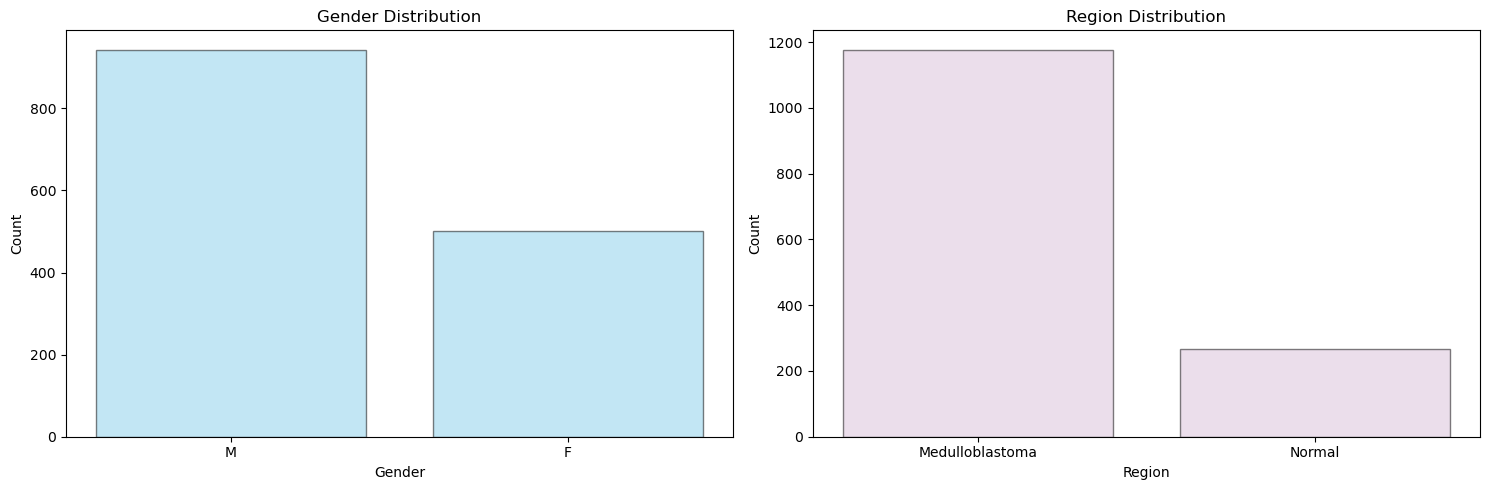

In [ ]:
# Barplot

import matplotlib.pyplot as plt
%matplotlib inline


valu_cou_g = merged_data["gender"].value_counts()
valu_cou_s = merged_data["source name"].value_counts()
valu_cou_b = merged_data["brain region"].value_counts()

fix, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].bar(valu_cou_g.index, valu_cou_g.values, color="skyblue", edgecolor="black", alpha = 0.5)
axes[0].set_title("Gender Distribution")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Count")

axes[1].bar(valu_cou_s.index, valu_cou_s.values, color="thistle", edgecolor="black", alpha = 0.5)
axes[1].set_title("Region Distribution")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Count")


plt.tight_layout()
plt.show()

Save Dataset


In [23]:
merged_data.to_csv("Pro_Data.csv", index=False)